# Лабораторна робота №3: Оптимізація та регуляризація на CIFAR (PyTorch)

## Мета роботи
Засобами **PyTorch** навчити повнозв'язну (FFN) та згорткову (CNN) мережі з шарами нормалізації для класифікації підмножини CIFAR-10. Порівняти алгоритми оптимізації, методи регуляризації (L1, L2, Dropout) та розклади швидкості навчання, відстежуючи криві втрат і точність на навчальній та валідаційній вибірках.

## Короткі теоретичні відомості
- **Функція втрат:** перехресна ентропія $\mathcal{L} = -\log \frac{\exp(z_y)}{\sum_j \exp(z_j)}$ для логітів $z$ та правильного класу $y$.
- **Оптимізатори:** SGD оновлює ваги за правилом $w \leftarrow w - \eta g$. RMSprop ділить крок на корінь із ковзного середнього квадратів градієнта. Adam додатково усереднює сам градієнт (момент) і виправляє зміщення обох оцінок.
- **Регуляризація:** L1 додає до втрат штраф $\lambda \sum |w|$ (розріджує ваги), L2 додає $\frac{\lambda}{2} \sum w^2$ (зменшує великі ваги), Dropout під час навчання випадково обнуляє частку $p$ активацій.
- **Розклади швидкості навчання:** ступінчастий $\eta_t = \eta_0 \gamma^{\lfloor t / s \rfloor}$ та косинусний $\eta_t = \frac{\eta_0}{2}\left(1 + \cos \frac{\pi t}{T}\right)$.
- **Пакетна нормалізація:** $\hat{z} = \frac{z - \mu_B}{\sqrt{\sigma_B^2 + \epsilon}}$, $y = \gamma \hat{z} + \beta$, де статистики рахуються за міні-батчем. Стабілізує розподіл активацій і пришвидшує навчання.

## 0. Налаштування середовища
Якщо папки `data` немає, завантажуємо дані змагання через Kaggle CLI. У Google Colab токен береться із Secrets (`KAGGLE_API_TOKEN`). `SUBMIT = True` вмикає відправку `submission.csv` на Kaggle наприкінці.

In [1]:
import os
import sys

COMPETITION = "lab-3-cifar"
SUBMIT = False  # set True to upload submission.csv to Kaggle at the end

if "google.colab" in sys.modules:
    from google.colab import userdata

    os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
    %pip install -q -U kaggle
!test -d data || (kaggle competitions download -c {COMPETITION} -p data && unzip -q data/{COMPETITION}.zip -d data)

## 1. Завантаження даних
Зображення $32 \times 32 \times 3$ стандартизуємо поканально за статистиками навчальної вибірки та розділимо `train` на навчальну (80%) і валідаційну (20%) частини.

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image

DATA_DIR = Path("data")
DEVICE = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"


def load_images(split: str, ids: np.ndarray) -> torch.Tensor:
    images = np.stack([np.asarray(Image.open(DATA_DIR / split / split / f"{i}.png")) for i in ids])
    return torch.tensor(images).permute(0, 3, 1, 2).float() / 255


train_meta = np.loadtxt(DATA_DIR / "train.csv", delimiter=",", skiprows=1, dtype=int)
test_ids = np.loadtxt(DATA_DIR / "test.csv", delimiter=",", skiprows=1, dtype=int)
x_all, y_all = load_images("train", train_meta[:, 0]), torch.tensor(train_meta[:, 1])
x_test = load_images("test", test_ids)

mean, std = x_all.mean(dim=(0, 2, 3), keepdim=True), x_all.std(dim=(0, 2, 3), keepdim=True)
x_all, x_test = ((x_all - mean) / std).to(DEVICE), ((x_test - mean) / std).to(DEVICE)
y_all = y_all.to(DEVICE)

perm = torch.randperm(len(x_all), generator=torch.Generator().manual_seed(42))
va, tr = perm[: len(perm) // 5], perm[len(perm) // 5 :]
x_tr, y_tr, x_va, y_va = x_all[tr], y_all[tr], x_all[va], y_all[va]
print(f"Пристрій: {DEVICE}, train: {len(x_tr)}, validation: {len(x_va)}, test: {len(x_test)}")

Пристрій: mps, train: 3200, validation: 800, test: 5000


## 2. Моделі та цикл навчання
Обидві мережі містять шари нормалізації: `BatchNorm1d` у FFN та `BatchNorm2d` у CNN.

In [3]:
def make_ffn(dropout: float = 0.0) -> nn.Sequential:
    return nn.Sequential(
        nn.Flatten(),
        nn.Linear(3 * 32 * 32, 512), nn.BatchNorm1d(512), nn.ReLU(), nn.Dropout(dropout),
        nn.Linear(512, 256), nn.BatchNorm1d(256), nn.ReLU(), nn.Dropout(dropout),
        nn.Linear(256, 10),
    )


def make_cnn(dropout: float = 0.3) -> nn.Sequential:
    def block(c_in: int, c_out: int) -> list[nn.Module]:
        return [nn.Conv2d(c_in, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(), nn.MaxPool2d(2)]

    return nn.Sequential(
        *block(3, 32), *block(32, 64), *block(64, 128),
        nn.Flatten(), nn.Dropout(dropout), nn.Linear(128 * 4 * 4, 10),
    )


OPTIMIZERS = {
    "SGD": lambda params, wd: torch.optim.SGD(params, lr=0.05, weight_decay=wd),
    "RMSprop": lambda params, wd: torch.optim.RMSprop(params, lr=1e-3, weight_decay=wd),
    "Adam": lambda params, wd: torch.optim.Adam(params, lr=1e-3, weight_decay=wd),
}
SCHEDULES = {
    "Constant": lambda opt, epochs: torch.optim.lr_scheduler.ConstantLR(opt, factor=1.0),
    "Step decay": lambda opt, epochs: torch.optim.lr_scheduler.StepLR(opt, step_size=epochs // 4, gamma=0.5),
    "Cosine annealing": lambda opt, epochs: torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs),
}


def train_model(model_fn, optimizer="Adam", schedule="Constant", l1=0.0, l2=0.0, epochs=20, batch=128):
    torch.manual_seed(42)
    model = model_fn().to(DEVICE)
    opt = OPTIMIZERS[optimizer](model.parameters(), l2)  # weight_decay in these optimizers is the L2 penalty
    sched = SCHEDULES[schedule](opt, epochs)
    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    for _ in range(epochs):
        model.train()
        loss_sum, correct = 0.0, 0
        for idx in torch.randperm(len(x_tr), device=DEVICE).split(batch):
            logits = model(x_tr[idx])
            loss = F.cross_entropy(logits, y_tr[idx])
            penalty = l1 * sum(p.abs().sum() for p in model.parameters() if p.ndim > 1)
            opt.zero_grad()
            (loss + penalty).backward()
            opt.step()
            loss_sum += loss.item() * len(idx)
            correct += (logits.argmax(1) == y_tr[idx]).sum().item()
        sched.step()

        model.eval()
        with torch.no_grad():
            logits = model(x_va)
        hist["train_loss"].append(loss_sum / len(x_tr))
        hist["train_acc"].append(correct / len(x_tr))
        hist["val_loss"].append(F.cross_entropy(logits, y_va).item())
        hist["val_acc"].append((logits.argmax(1) == y_va).float().mean().item())
    return model, hist


def report(runs: dict[str, tuple[nn.Module, dict]], title: str) -> None:
    """Print final metrics and plot loss curves and train vs validation accuracy."""
    print(f"{title:<18} | Train acc | Val acc | Val loss")
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    for i, (name, (_, h)) in enumerate(runs.items()):
        print(f"{name:<18} | {h['train_acc'][-1]:9.3f} | {h['val_acc'][-1]:7.3f} | {h['val_loss'][-1]:8.3f}")
        for ax, key in zip(axes, ("loss", "acc")):
            ax.plot(h[f"train_{key}"], "--", color=f"C{i}")
            ax.plot(h[f"val_{key}"], color=f"C{i}", label=name)
    for ax, name in zip(axes, ("Втрати", "Точність")):
        ax.set_title(f"{title}: {name.lower()} (пунктир train, суцільна validation)")
        ax.set_xlabel("Епоха")
        ax.legend()
        ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

## 3. Порівняння оптимізаторів
Навчимо FFN без регуляризації трьома оптимізаторами.

Оптимізатор        | Train acc | Val acc | Val loss
SGD                |     0.971 |   0.417 |    2.099
RMSprop            |     0.973 |   0.394 |    2.516
Adam               |     0.986 |   0.357 |    2.763


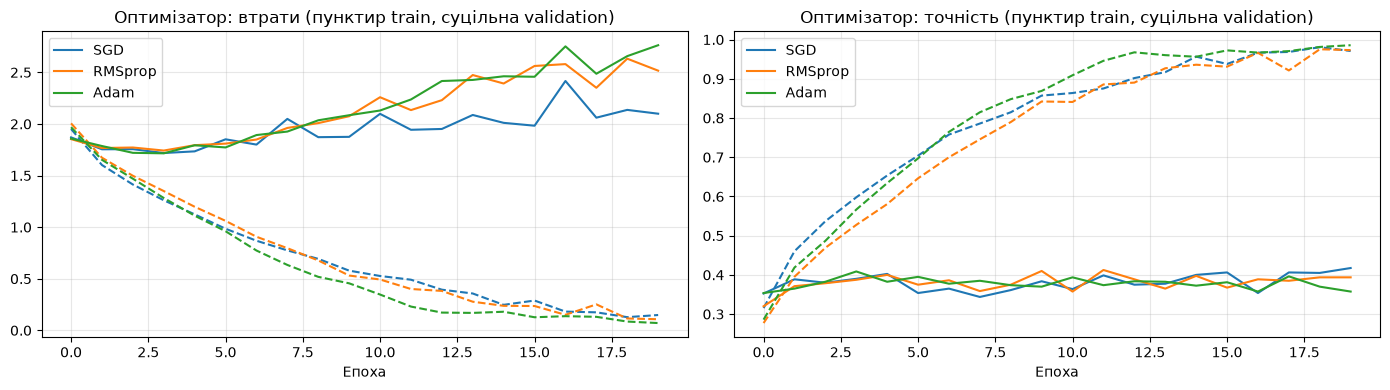

In [4]:
opt_runs = {name: train_model(make_ffn, optimizer=name) for name in OPTIMIZERS}
report(opt_runs, "Оптимізатор")

## 4. Регуляризація
Порівняємо FFN без регуляризації, з L1-штрафом ($\lambda = 10^{-4}$), з L2-штрафом ($\lambda = 10^{-2}$) та з Dropout ($p = 0.5$). Оптимізатор Adam.

Регуляризація      | Train acc | Val acc | Val loss
Без регуляризації  |     0.986 |   0.357 |    2.763
L1                 |     0.850 |   0.381 |    2.333
L2                 |     0.771 |   0.365 |    1.973
Dropout            |     0.660 |   0.403 |    1.717


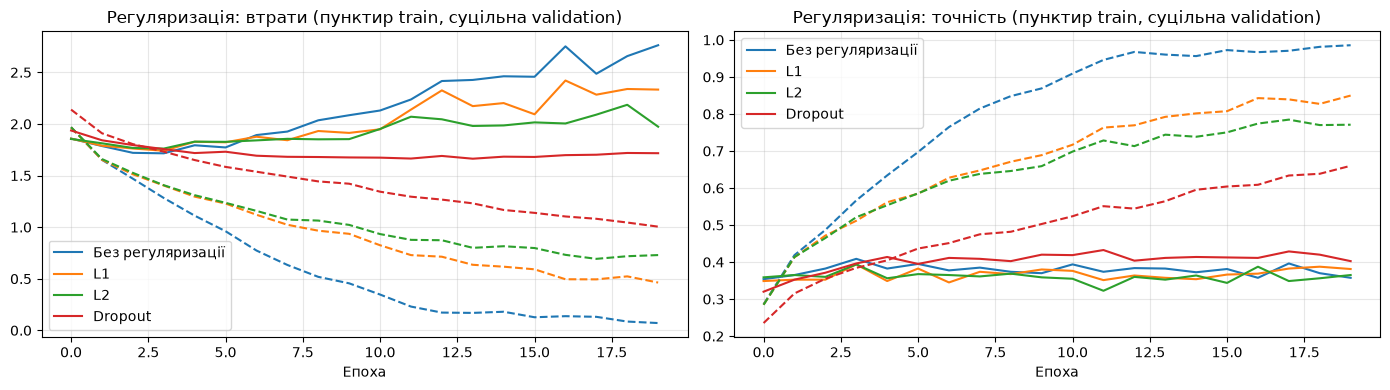

In [5]:
reg_runs = {
    "Без регуляризації": train_model(make_ffn),
    "L1": train_model(make_ffn, l1=1e-4),
    "L2": train_model(make_ffn, l2=1e-2),
    "Dropout": train_model(lambda: make_ffn(dropout=0.5)),
}
report(reg_runs, "Регуляризація")

## 5. Розклади швидкості навчання
Порівняємо постійний крок, ступінчасте зменшення (удвічі кожні 5 епох) та косинусний розклад для FFN із Dropout та оптимізатором Adam.

Розклад            | Train acc | Val acc | Val loss
Constant           |     0.660 |   0.403 |    1.717
Step decay         |     0.641 |   0.444 |    1.625
Cosine annealing   |     0.664 |   0.438 |    1.632


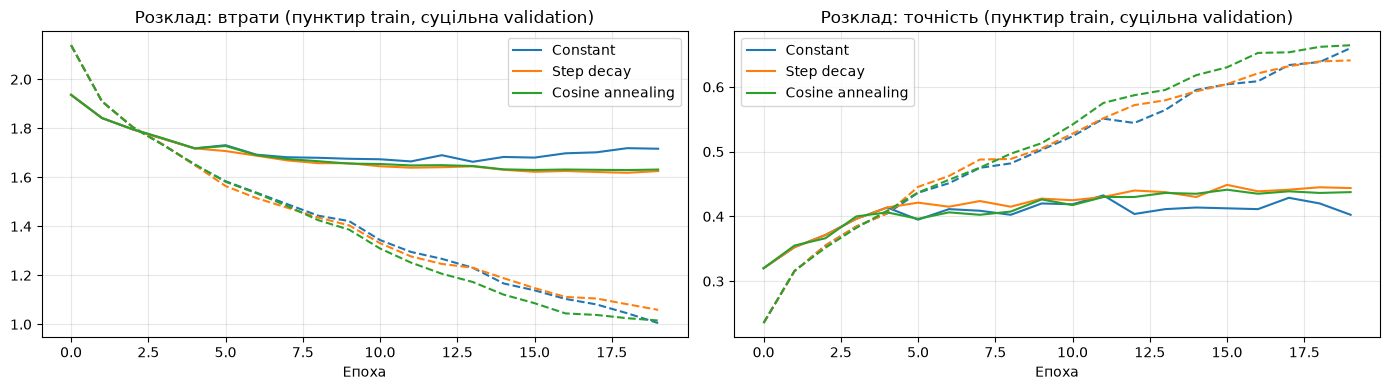

In [6]:
sched_runs = {name: train_model(lambda: make_ffn(dropout=0.5), schedule=name) for name in SCHEDULES}
report(sched_runs, "Розклад")

## 6. Згорткова мережа
Навчимо CNN (три блоки `Conv2d -> BatchNorm2d -> ReLU -> MaxPool2d`, Dropout, Adam, косинусний розклад) і порівняємо її з FFN з попереднього розділу, навченою з тим самим розкладом.

Архітектура        | Train acc | Val acc | Val loss
FFN                |     0.664 |   0.438 |    1.632
CNN                |     0.962 |   0.584 |    1.175


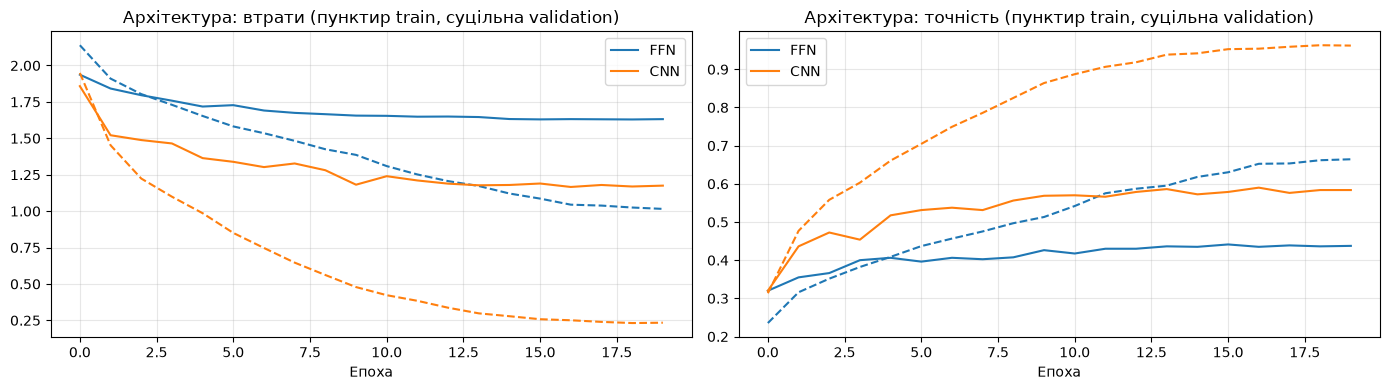

In [7]:
cnn_runs = {
    "FFN": sched_runs["Cosine annealing"],
    "CNN": train_model(make_cnn, schedule="Cosine annealing"),
}
report(cnn_runs, "Архітектура")

## 7. Формування `submission.csv`
Прогноз для тестової вибірки робимо згортковою мережею.

In [8]:
cnn = cnn_runs["CNN"][0]
with torch.no_grad():
    labels = torch.cat([cnn(xb).argmax(1) for xb in x_test.split(500)]).cpu().numpy()
np.savetxt("submission.csv", np.column_stack([test_ids, labels]), delimiter=",", header="id,label", comments="", fmt="%d")
print(f"submission.csv збережено, рядків: {len(labels)}")

submission.csv збережено, рядків: 5000


Відправка на Kaggle (при `SUBMIT = True`) та перелік відправок:

In [9]:
if SUBMIT:
    !kaggle competitions submit -c {COMPETITION} -f submission.csv -m "Lab 3 CNN submission"
!kaggle competitions submissions -c {COMPETITION}

     ref  fileName        date                        description           status                     publicScore  privateScore  
--------  --------------  --------------------------  --------------------  -------------------------  -----------  ------------  
58855103  submission.csv  2026-11-24 23:52:51.477000  Lab 3 CNN submission  SubmissionStatus.COMPLETE  0.63040      0.62120       


## Висновки
1. **Оптимізатори.** Без регуляризації FFN з усіма оптимізаторами запам'ятовує навчальну вибірку (точність 0.97..0.99), а валідаційні втрати зростають. Найкращу валідаційну точність має `SGD` (0.417), далі `RMSprop` (0.394) і `Adam` (0.357): адаптивні методи швидше підганяють навчальні дані та сильніше перенавчаються.
2. **Регуляризація.** Усі методи зменшують розрив між навчальною та валідаційною точністю: без регуляризації 0.986 проти 0.357, L1 0.850 проти 0.381, L2 0.771 проти 0.365, Dropout 0.660 проти 0.403. Dropout найефективніший і знижує валідаційні втрати з 2.763 до 1.717.
3. **Розклади швидкості навчання.** Зменшення кроку під час навчання покращує результат порівняно з постійним кроком (0.403): ступінчастий розклад дає 0.444, косинусний 0.438, валідаційні втрати падають з 1.717 до 1.63.
4. **FFN та CNN.** Згорткова мережа з `BatchNorm2d` суттєво випереджає повнозв'язну: валідаційна точність 0.584 проти 0.438, втрати 1.175 проти 1.632. CNN також перенавчається (навчальна точність 0.962), що очікувано для 3200 навчальних зображень.